# Decision Tree

A single decision tree: a flowchart of yes/no questions on feature thresholds (e.g. "is `same_srv_rate` ≤ 0.3?"), learned by picking at each step the split that best separates normal from DoS rows (Gini impurity). Thresholds don't care about scale, so no `StandardScaler` is needed.

It is the building block of Random Forest (notebook 04), which averages hundreds of these trees. Defined in `src/models.py` as `decision_tree()`; grown to full depth by default.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.models import MODELS
from dosdetect.report import metrics_table, plot_confusion, run
from dosdetect.run import prepare

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only. Two test setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types the model never saw in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: a stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.

The paper keeps the 8 features most correlated with the label. We also try all 41.

In [2]:
data = {
    (split, n): prepare(split, n_features=n) for split in ("official", "holdout") for n in (8, 41)
}
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

Same model, all four setups. `recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results, matrices = {}, {}
for (split, n), d in data.items():
    r = run(MODELS["decision_tree"](), d)
    matrices[(split, n)] = r.pop("confusion_matrix")
    results[f"{split}, {n} features"] = r
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8531,0.9802,0.6755,0.7998,0.8150,0.2091,0.2233,0.0040
"official, 41 features",0.9054,0.9784,0.7999,0.8802,0.9873,0.1736,0.7849,0.0051
"holdout, 8 features",0.9602,0.9850,0.9158,0.9492,NaN,NaN,0.1302,0.0040
"holdout, 41 features",0.9997,0.9996,0.9997,0.9996,NaN,NaN,0.4319,0.0021


### Confusion matrices

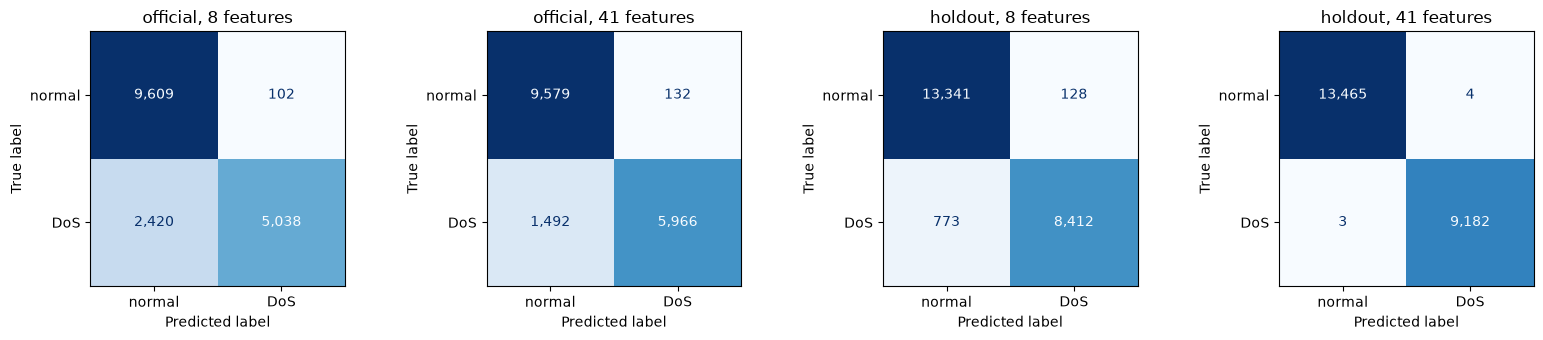

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (key, cm) in zip(axes, matrices.items(), strict=True):
    plot_confusion(cm, f"{key[0]}, {key[1]} features", ax=ax)
plt.tight_layout()

## Tree depth

A full-depth tree can memorise the training data. Limiting depth makes it simpler. Official and holdout splits, 8 features.

In [5]:
from sklearn.tree import DecisionTreeClassifier

depths = [2, 4, 6, 8, 10, 15, 20, None]
rows = {}
for depth in depths:
    for split in ("official", "holdout"):
        r = run(DecisionTreeClassifier(max_depth=depth, random_state=42), data[(split, 8)])
        rows[(str(depth), split)] = r["accuracy"]
depth_table = pd.Series(rows).unstack()
depth_table.index.name = "max_depth"
depth_table.loc[[str(d) for d in depths]]

,holdout,official
max_depth,,
2,0.9547,0.8330
4,0.9561,0.8333
6,0.9552,0.8533
8,0.9576,0.8551
10,0.9590,0.8546
15,0.9609,0.8538
20,0.9618,0.8537
None,0.9602,0.8531


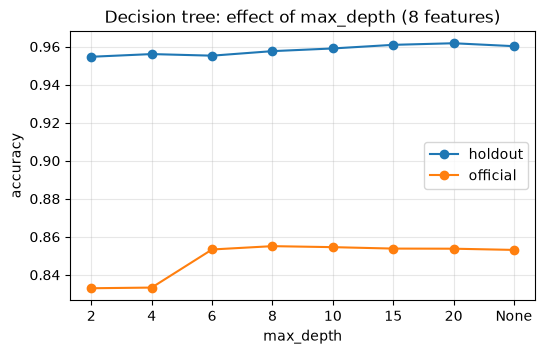

In [6]:
ax = depth_table.loc[[str(d) for d in depths]].plot(marker="o", figsize=(6, 3.5))
ax.set_ylabel("accuracy")
ax.set_title("Decision tree: effect of max_depth (8 features)")
ax.grid(alpha=0.3)

## What the tree learned

The top three levels of the full tree (official training data, 8 features). Each box shows the split question, the Gini impurity, and how many rows reach it.

Depth: 39  Leaves: 1728


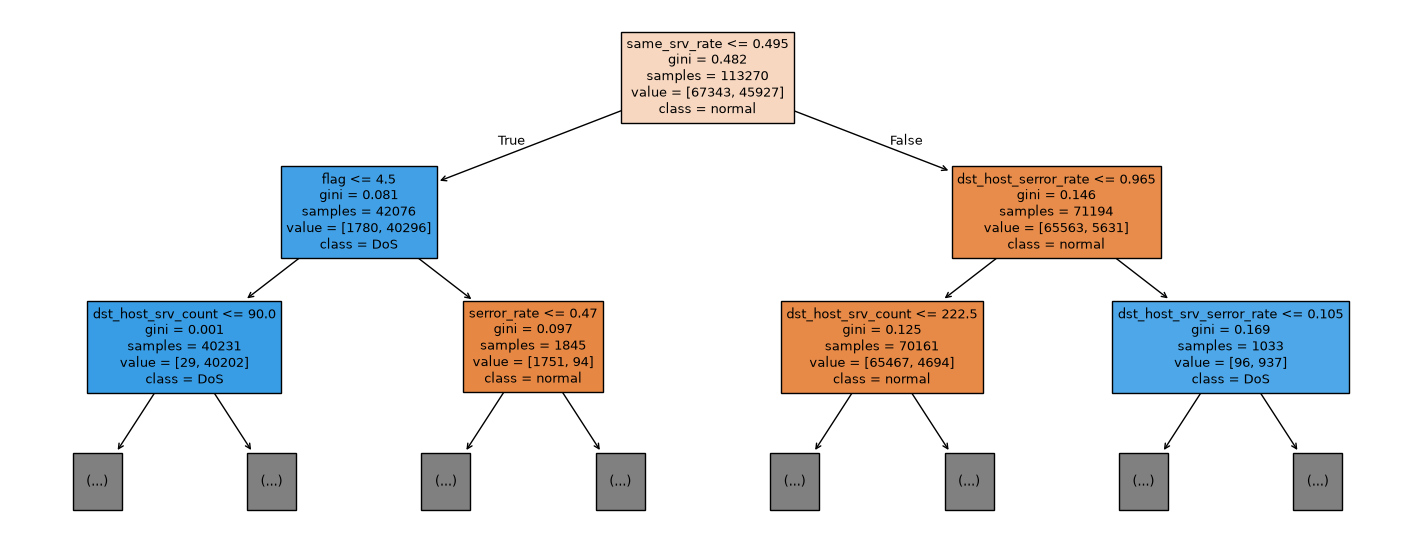

In [7]:
from sklearn.tree import plot_tree

tree = MODELS["decision_tree"]().fit(official["X_train"], official["y_train"])
print("Depth:", tree.get_depth(), " Leaves:", tree.get_n_leaves())
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    tree,
    max_depth=2,
    feature_names=list(official["X_train"].columns),
    class_names=["normal", "DoS"],
    filled=True,
    impurity=True,
    fontsize=9,
    ax=ax,
);

In [8]:
pd.Series(
    tree.feature_importances_, index=official["X_train"].columns, name="importance"
).sort_values(ascending=False).to_frame()

,importance
same_srv_rate,0.8309
flag,0.0718
dst_host_serror_rate,0.0395
dst_host_srv_count,0.0278
dst_host_same_srv_rate,0.0176
serror_rate,0.0063
dst_host_srv_serror_rate,0.0059
srv_serror_rate,0.0003


## Takeaways

- **As accurate as the Random Forest from a single tree.** 96.0% on the holdout split (8 features), 90.5% on the official file with 41 features, within 0.3 points of Random Forest in both setups. It trains in under 0.5 s, about 10x faster than the forest.
- **Unseen attacks are still the weak spot**: 17–21% recall on never-seen DoS types. The tree learns thresholds that fit known attacks and has no reason to flag traffic outside them.
- **Depth barely matters past 6.** Official accuracy stays between 85.3% and 85.5% from depth 6 to full depth (39 levels, 1,728 leaves). A depth-6 tree is far easier to read and explain in a forensics report.
- **One feature does most of the work.** `same_srv_rate` (share of recent connections to the same service) accounts for 83% of the tree's importance, followed by `flag`. DoS floods hammer one service, so this is an easy feature to justify to an investigator.